In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)


cuda


In [2]:
BATCH_SIZE = 128

transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
])

train_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=transform_test
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')


100%|██████████| 170M/170M [22:19<00:00, 127kB/s]


train: 50000
test: 10000
(C, H, W): torch.Size([3, 32, 32])


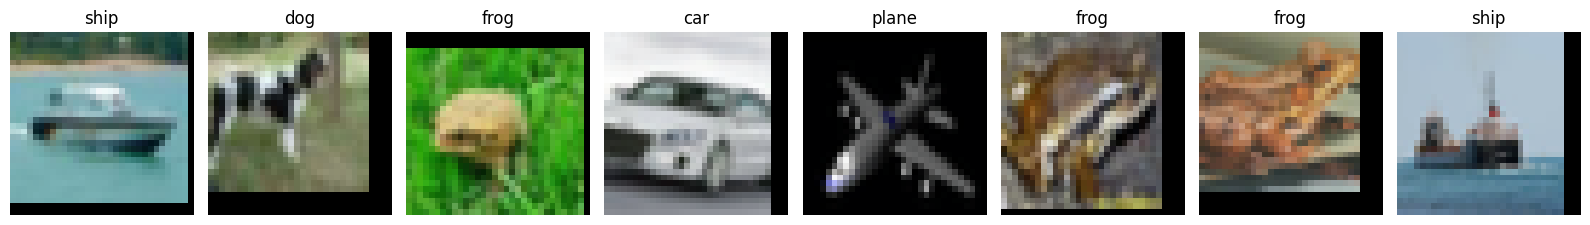

In [3]:

print(f'train: {len(train_dataset)}')
print(f'test: {len(test_dataset)}')

sample_img, sample_label = train_dataset[0]
print(f'(C, H, W): {sample_img.shape}')

def imshow(img):
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2023, 0.1994, 0.2010])
    img = img.numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img
dataiter = iter(train_loader)
images, labels = next(dataiter)

fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for i in range(8):
    axes[i].imshow(imshow(images[i]))
    axes[i].set_title(classes[labels[i]])
    axes[i].axis('off')
plt.tight_layout()
plt.show()


In [4]:
class CustomCIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super(CustomCIFAR10CNN, self).__init__()

        # 3x32x32 -> 64x16x16
        self.block1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # 64x16x16 -> 128x8x8
        self.block2 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        #  128x8x8 -> 256x4x4
        self.block3 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        # Flatten: 256 * 4 * 4 = 4096
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.4),
            nn.Linear(256 * 4 * 4, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classifier(x)
        return x

model = CustomCIFAR10CNN(num_classes=10).to(device)
print(model)


CustomCIFAR10CNN(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size

In [5]:
EPOCHS = 20
LEARNING_RATE = 0.001
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.5)


In [6]:
train_loss_history = []
train_acc_history = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    scheduler.step()

    epoch_loss = running_loss / total
    epoch_acc = 100.0 * correct / total
    train_loss_history.append(epoch_loss)
    train_acc_history.append(epoch_acc)

    print(f"Эпоха [{epoch+1:02d}/{EPOCHS:02d}] | "
          f"Train Loss: {epoch_loss:.4f} | "
          f"Train Accuracy: {epoch_acc:.2f}%")


Эпоха [01/20] | Train Loss: 1.2645 | Train Accuracy: 54.27%
Эпоха [02/20] | Train Loss: 0.8297 | Train Accuracy: 70.83%
Эпоха [03/20] | Train Loss: 0.6951 | Train Accuracy: 75.72%
Эпоха [04/20] | Train Loss: 0.6057 | Train Accuracy: 79.02%
Эпоха [05/20] | Train Loss: 0.5553 | Train Accuracy: 80.68%
Эпоха [06/20] | Train Loss: 0.5033 | Train Accuracy: 82.71%
Эпоха [07/20] | Train Loss: 0.4709 | Train Accuracy: 83.87%
Эпоха [08/20] | Train Loss: 0.3780 | Train Accuracy: 86.99%
Эпоха [09/20] | Train Loss: 0.3469 | Train Accuracy: 87.99%
Эпоха [10/20] | Train Loss: 0.3316 | Train Accuracy: 88.45%
Эпоха [11/20] | Train Loss: 0.3112 | Train Accuracy: 89.22%
Эпоха [12/20] | Train Loss: 0.2977 | Train Accuracy: 89.73%
Эпоха [13/20] | Train Loss: 0.2862 | Train Accuracy: 90.02%
Эпоха [14/20] | Train Loss: 0.2711 | Train Accuracy: 90.50%
Эпоха [15/20] | Train Loss: 0.2173 | Train Accuracy: 92.52%
Эпоха [16/20] | Train Loss: 0.1983 | Train Accuracy: 93.17%
Эпоха [17/20] | Train Loss: 0.1915 | Tra


Результаты на тестовой выборке:
Test Loss: 0.3185
Test Accuracy: 89.80%


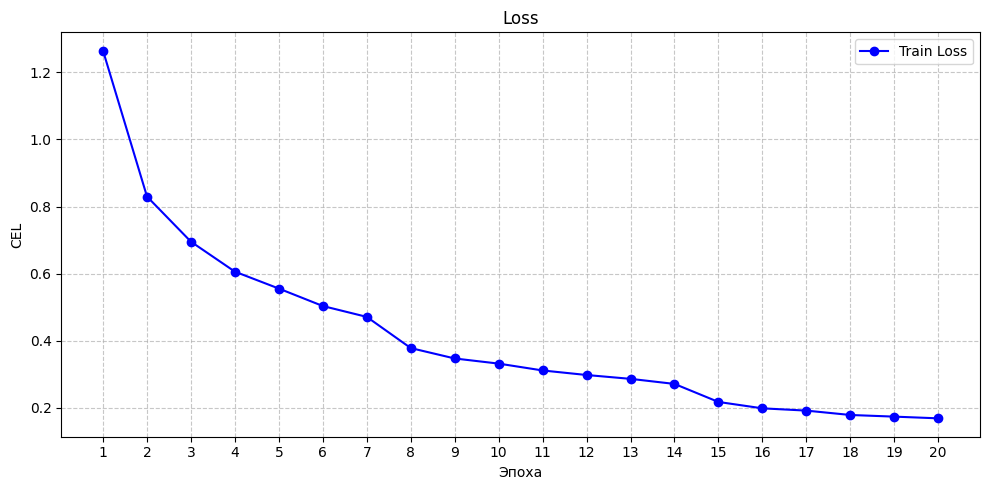

In [7]:
model.eval()
test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

final_test_loss = test_loss / total
final_test_acc = 100.0 * correct / total

print(f"\nРезультаты на тестовой выборке:")
print(f"Test Loss: {final_test_loss:.4f}")
print(f"Test Accuracy: {final_test_acc:.2f}%")

plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), train_loss_history, marker='o', color='b', label='Train Loss')
plt.title('Loss')
plt.xlabel('Эпоха')
plt.ylabel('CEL')
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()
